# ĐỒ ÁN 1: PHÂN TÍCH NHÂN KHẨU HỌC VÀ DỰ ĐOÁN MỨC THU NHẬP CÁ NHÂN (US ADULT CENSUS)
**Nhóm thực hiện: 1_2 - Lớp: DHKL18A1HN**
- Đào Đoàn Huy Phúc (Trưởng nhóm)
- Mai Đức Nhân
- Cao Nguyên Ngọc
- Nguyễn Văn Dũng (MSV: 22174600097)
- Trịnh Phương Thùy


In [1]:
# Cấu hình thư viện ban đầu
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
%matplotlib inline


# Chương 1: thu thập dữ liệu



##1.1. Đọc dữ liệu

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/34-DaoDoanHuyPhuc-24174600034/Do-an-1-nhom-1_2-DHKL18A1HN/master/adult.csv", na_values='?')
df

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,<=50K
32557,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32558,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32559,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K


##1.2. hiển thị thông tin chi tiết về các cột

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


##1.3. Thống kê mô tả các biến số và biến phân loại

In [4]:
df.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [5]:
df.describe(include=['object'])

,workclass,education,marital.status,occupation,relationship,race,sex,native.country,income
count,30725,32561,32561,30718,32561,32561,32561,31978,32561
unique,8,16,7,14,6,5,2,41,2
top,Private,HS-grad,Married-civ-spouse,Prof-specialty,Husband,White,Male,United-States,<=50K
freq,22696,10501,14976,4140,13193,27816,21790,29170,24720


# Chương 2: Làm sạch và tiền xử dữ liệu

## import thư viện

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.feature_selection import VarianceThreshold
from statsmodels.stats.outliers_influence import variance_inflation_factor
import warnings
warnings.filterwarnings('ignore')

##2.1. Phân tích giá trị còn thiếu

In [7]:
missing = df.isnull().sum()
pd.DataFrame({'Số lượng thiếu': missing,
              'Tỷ lệ (%)': missing / len(df) * 100})

,Số lượng thiếu,Tỷ lệ (%)
age,0,0.000000
workclass,1836,5.638647
fnlwgt,0,0.000000
education,0,0.000000
education.num,0,0.000000
marital.status,0,0.000000
occupation,1843,5.660146
relationship,0,0.000000
race,0,0.000000
sex,0,0.000000


###2.1.1. Phân tích sâu về giá trị thiếu "?"
**Vấn đề:** Dataset chứa ký tự `?` ở 3 cột: `workclass`, `occupation`, `native-country`.
Thay vì vội vàng thay thế bằng Mode (giá trị phổ biến nhất) hoặc xóa dòng, chúng ta cần kiểm định xem việc "không điền thông tin" (`?`) có mang ý nghĩa thống kê đối với biến mục tiêu (`income`) hay không.

In [8]:
for col in ['workclass', 'occupation', 'native.country']:
    missing = df[col].isna() | (df[col] == '?')
    print(f'{col}: Thiếu {missing.sum()} ({missing.mean()*100:.2f}%), '
        f'tỷ lệ >50K: {((df.loc[missing, "income"] == ">50K").mean()*100):.2f}%'
        )

workclass: Thiếu 1836 (5.64%), tỷ lệ >50K: 10.40%
occupation: Thiếu 1843 (5.66%), tỷ lệ >50K: 10.36%
native.country: Thiếu 583 (1.79%), tỷ lệ >50K: 25.04%


#### Kết luận về cơ chế thiếu dữ liệu

Kết quả phân tích sơ bộ cho thấy các nhóm có giá trị thiếu (`?`) ở các biến `workclass`, `occupation` và `native-country` có thể có phân phối thu nhập khác với các nhóm có thông tin đầy đủ.

Đối với `workclass` và `occupation`, tỷ lệ cá nhân có thu nhập trên 50K trong nhóm thiếu thông tin lần lượt khoảng 10,4% và 10,3%, thấp hơn mức trung bình chung khoảng 22%

--> Có thể thấy rằng tình trạng thiếu dữ liệu có mối liên hệ với biến thu nhập.

Tuy nhiên, kết quả này chưa đủ để xác định cơ chế thiếu dữ liệu là MCAR, MAR hay MNAR. Cần phân tích thêm mối liên hệ giữa tình trạng thiếu dữ liệu và các biến quan sát được.

**Chiến lược xử lý:** Giữ giá trị `?` như một nhóm riêng hoặc chuyển thành `Unknown` để tránh tự ý gán giá trị chưa biết thành một danh mục cụ thể. Sau đó, đánh giá hiệu quả của cách xử lý này trên mô hình dự đoán.

In [9]:
cols_to_check=['workclass','occupation','native.country']
df_model = df.copy()
df_model[cols_to_check] = df_model[cols_to_check].fillna('Unknown')
print(df_model.shape, (df_model[cols_to_check] == 'Unknown').sum().sum())

(32561, 15) 4262


# Chương 3: Phân tích thống kê và trực quan hóa số lượng, tỷ lệ

Biến mục tiêu `income` có 2 lớp:
- `<=50K`: Thu nhập thấp hoặc trung bình
- `>50K`: Thu nhập cao

Việc phân tích phân phối này giúp chúng ta hiểu:
- Dataset có bị mất cân bằng lớp (imbalanced) không?
- Tỷ lệ baseline accuracy là bao nhiêu?**văn bản in đậm**

In [10]:
print('Đếm số lượng')
print(df_model['income'].value_counts())

print('\nTỉ lệ phần trăm')
df_model['income'].value_counts(normalize=True) * 100

Đếm số lượng
income
<=50K    24720
>50K      7841
Name: count, dtype: int64

Tỉ lệ phần trăm


income
<=50K    75.919044
>50K     24.080956
Name: proportion, dtype: float64

NHẬN XÉT:
- Dataset bị mất cân bằng lớp: ~76% <=50K, ~24% >50K
- Baseline accuracy: ~76% (nếu dự đoán toàn bộ là <=50K)
- Cần chú ý đến các metric như Precision, Recall, F1-score thay vì chỉ Accuracy

## 3.1. Phân phối các biến phân loại (Categorical Variables)

In [11]:
print("PHÂN PHỐI GIỚI TÍNH (SEX):")

print('Đếm số lượng')
print(df_model['sex'].value_counts())

print('\nTỉ lệ phần trăm')
df_model['sex'].value_counts(normalize=True) * 100

PHÂN PHỐI GIỚI TÍNH (SEX):
Đếm số lượng
sex
Male      21790
Female    10771
Name: count, dtype: int64

Tỉ lệ phần trăm


sex
Male      66.920549
Female    33.079451
Name: proportion, dtype: float64

NHẬN XÉT:
- Nam giới chiếm đa số (~67%) trong dataset
- Có sự mất cân bằng giới tính, cần chú ý khi phân tích

In [12]:
print("PHÂN PHỐI TRÌNH ĐỘ HỌC VẤN (EDUCATION):")
df_model['education'].value_counts()

PHÂN PHỐI TRÌNH ĐỘ HỌC VẤN (EDUCATION):


education
HS-grad         10501
Some-college     7291
Bachelors        5355
Masters          1723
Assoc-voc        1382
11th             1175
Assoc-acdm       1067
10th              933
7th-8th           646
Prof-school       576
9th               514
12th              433
Doctorate         413
5th-6th           333
1st-4th           168
Preschool          51
Name: count, dtype: int64

NHẬN XÉT:
- HS-grad (tốt nghiệp cấp 3) là trình độ phổ biến nhất
- Some-college và Bachelors cũng chiếm tỷ lệ đáng kể
- Các trình độ cao như Masters, Doctorate chiếm tỷ lệ nhỏ

PHÂN PHỐI TÌNH TRẠNG HÔN NHÂN (marital,STATUS):
marital.status
Married-civ-spouse       14976
Never-married            10683
Divorced                  4443
Separated                 1025
Widowed                    993
Married-spouse-absent      418
Married-AF-spouse           23
Name: count, dtype: int64


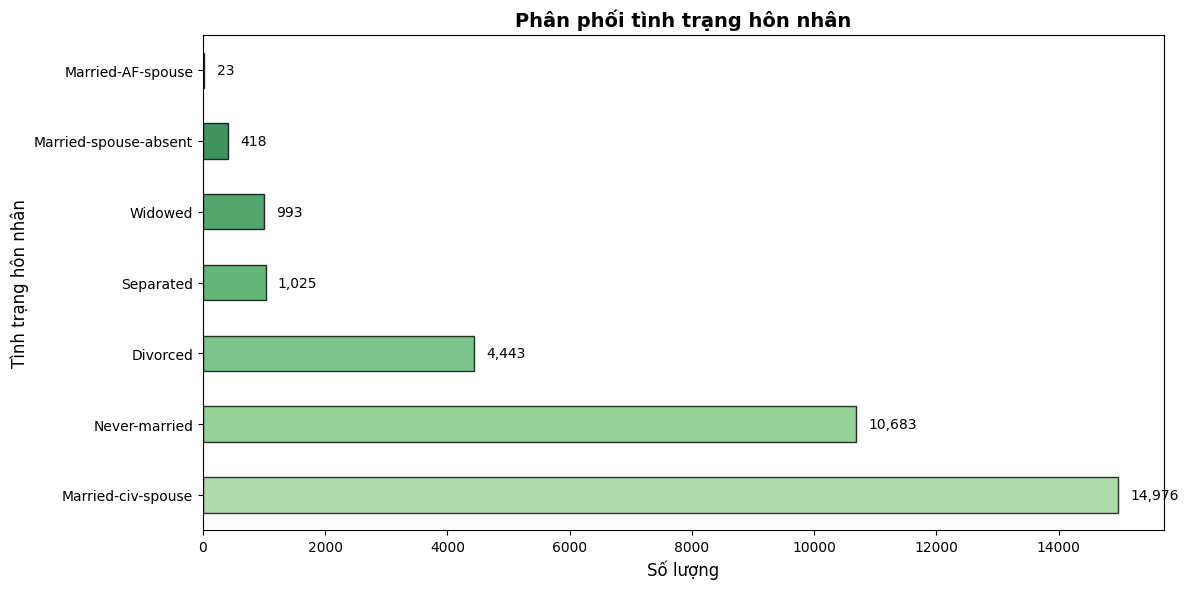

In [13]:
# Phân phối tình trạng hôn nhân
print("PHÂN PHỐI TÌNH TRẠNG HÔN NHÂN (marital,STATUS):")
print("=" * 70)
marital_counts = df_model['marital.status'].value_counts()
print(marital_counts)

fig, ax = plt.subplots(figsize=(12, 6))

colors = plt.cm.Greens(np.linspace(0.4, 0.9, len(marital_counts)))
marital_counts.plot(kind='barh', ax=ax, color=colors, edgecolor='black', alpha=0.8)
ax.set_title('Phân phối tình trạng hôn nhân', fontsize=14, fontweight='bold')
ax.set_xlabel('Số lượng', fontsize=12)
ax.set_ylabel('Tình trạng hôn nhân', fontsize=12)

# Thêm giá trị
for i, v in enumerate(marital_counts.values):
    ax.text(v + 200, i, f'{v:,}', va='center', fontsize=10)

plt.tight_layout()
plt.show()

PHÂN PHỐI NGHỀ NGHIỆP (OCCUPATION):
occupation
Prof-specialty       4140
Craft-repair         4099
Exec-managerial      4066
Adm-clerical         3770
Sales                3650
Other-service        3295
Machine-op-inspct    2002
Unknown              1843
Transport-moving     1597
Handlers-cleaners    1370
Farming-fishing       994
Tech-support          928
Protective-serv       649
Priv-house-serv       149
Armed-Forces            9
Name: count, dtype: int64


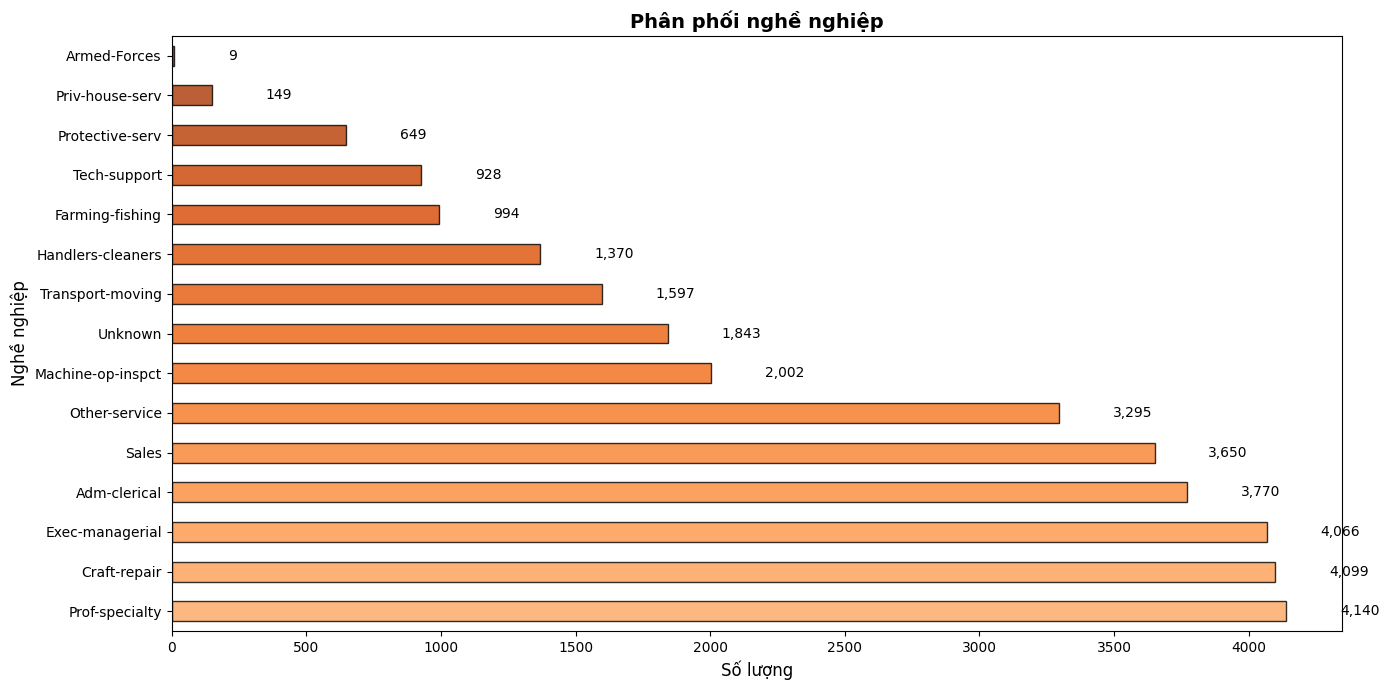


NHẬN XÉT:
- Craft-repair, Sales, Exec-managerial là các nghề phổ biến nhất
- Có sự đa dạng về nghề nghiệp trong dataset


In [14]:
# Phân phối nghề nghiệp
print("PHÂN PHỐI NGHỀ NGHIỆP (OCCUPATION):")
print("=" * 70)
occ_counts = df_model['occupation'].value_counts()
print(occ_counts)

fig, ax = plt.subplots(figsize=(14, 7))

colors = plt.cm.Oranges(np.linspace(0.4, 0.9, len(occ_counts)))
occ_counts.plot(kind='barh', ax=ax, color=colors, edgecolor='black', alpha=0.8)
ax.set_title('Phân phối nghề nghiệp', fontsize=14, fontweight='bold')
ax.set_xlabel('Số lượng', fontsize=12)
ax.set_ylabel('Nghề nghiệp', fontsize=12)

# Thêm giá trị
for i, v in enumerate(occ_counts.values):
    ax.text(v + 200, i, f'{v:,}', va='center', fontsize=10)

plt.tight_layout()
plt.show()

print("\nNHẬN XÉT:")
print("- Craft-repair, Sales, Exec-managerial là các nghề phổ biến nhất")
print("- Có sự đa dạng về nghề nghiệp trong dataset")

# Chương 4: Trực quan hóa phân phối đơn biến

### 4.1. Phân tích tuổi (age)

In [15]:
# Tính các giá trị thống kê cho biến tuổi
print("THỐNG KÊ CHI TIẾT - TUỔI (AGE):")
print("=" * 70)
age_stats = df_model['age'].describe()
print(age_stats)
print(f"\nTrung vị (Median): {df_model['age'].median():.1f}")
print(f"Độ lệch chuẩn (Std): {df_model['age'].std():.2f}")
print(f"Khoảng tứ phân vị (IQR): {df_model['age'].quantile(0.75) - df_model['age'].quantile(0.25):.1f}")

THỐNG KÊ CHI TIẾT - TUỔI (AGE):
count    32561.000000
mean        38.581647
std         13.640433
min         17.000000
25%         28.000000
50%         37.000000
75%         48.000000
max         90.000000
Name: age, dtype: float64

Trung vị (Median): 37.0
Độ lệch chuẩn (Std): 13.64
Khoảng tứ phân vị (IQR): 20.0


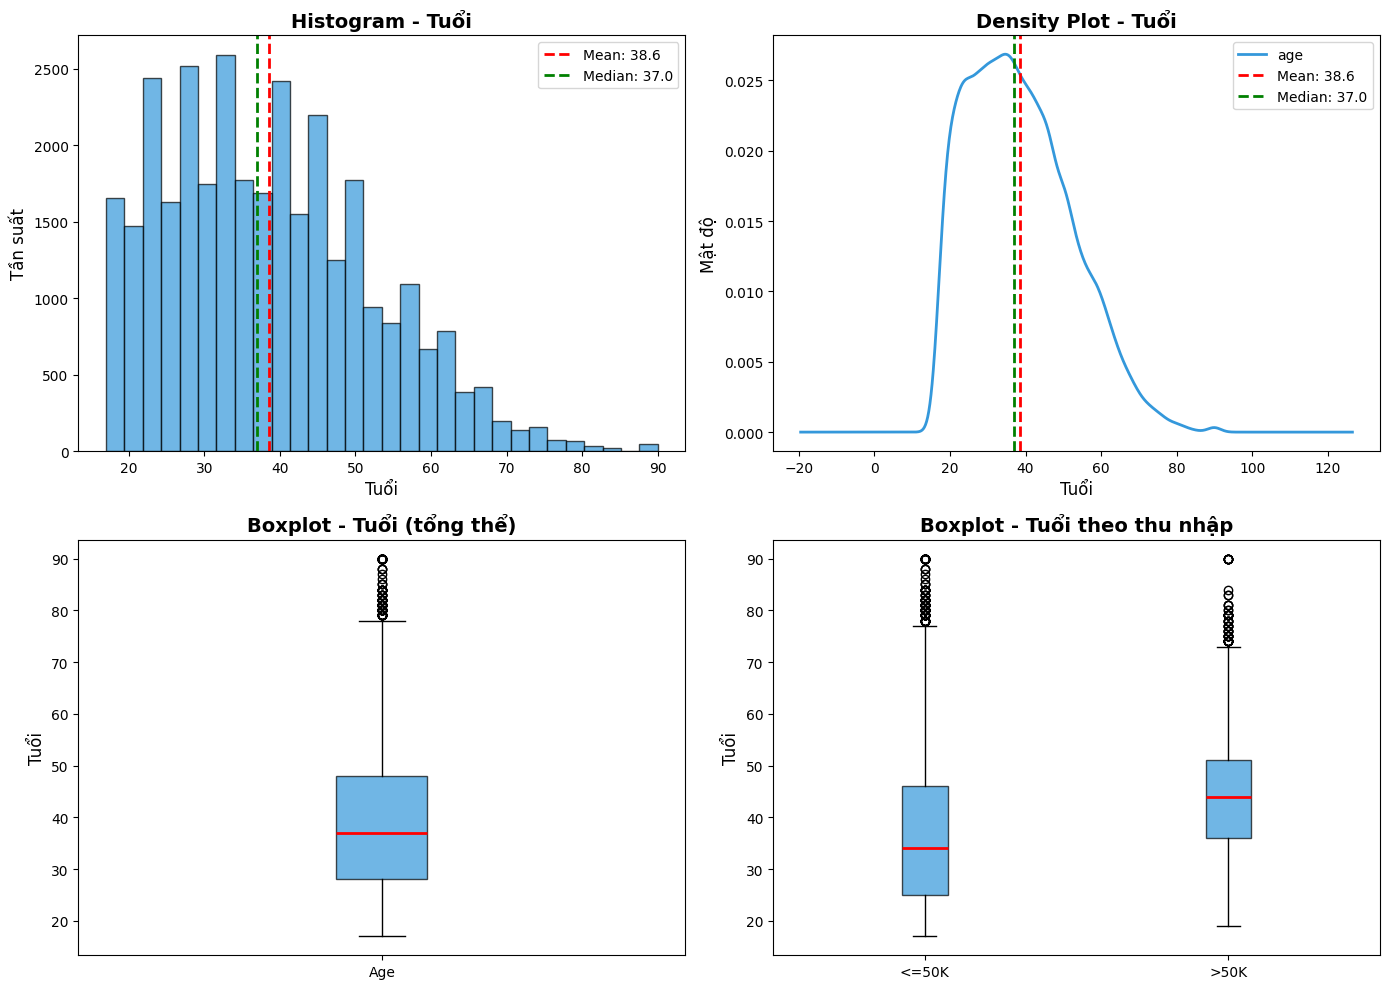


NHẬN XÉT:
- Phân phối tuổi lệch phải (right-skewed)
- Độ tuổi trung bình: ~38.6 tuổi, trung vị: ~37 tuổi
- Người có thu nhập >50K có xu hướng lớn tuổi hơn
- Có một số outliers ở độ tuổi cao (trên 70)


In [16]:
# Vẽ Histogram, Density Plot và Boxplot cho tuổi
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Histogram
axes[0, 0].hist(df_model['age'], bins=30, color='#3498db', edgecolor='black', alpha=0.7)
axes[0, 0].axvline(df_model['age'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df_model["age"].mean():.1f}')
axes[0, 0].axvline(df_model['age'].median(), color='green', linestyle='--', linewidth=2, label=f'Median: {df_model["age"].median():.1f}')
axes[0, 0].set_title('Histogram - Tuổi', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Tuổi', fontsize=12)
axes[0, 0].set_ylabel('Tần suất', fontsize=12)
axes[0, 0].legend()

# Density Plot
df_model['age'].plot(kind='density', ax=axes[0, 1], color='#3498db', linewidth=2)
axes[0, 1].axvline(df_model['age'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df_model["age"].mean():.1f}')
axes[0, 1].axvline(df_model['age'].median(), color='green', linestyle='--', linewidth=2, label=f'Median: {df_model["age"].median():.1f}')
axes[0, 1].set_title('Density Plot - Tuổi', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Tuổi', fontsize=12)
axes[0, 1].set_ylabel('Mật độ', fontsize=12)
axes[0, 1].legend()

# Boxplot tổng thể
axes[1, 0].boxplot(df_model['age'], vert=True, patch_artist=True,
                   boxprops=dict(facecolor='#3498db', alpha=0.7),
                   medianprops=dict(color='red', linewidth=2))
axes[1, 0].set_title('Boxplot - Tuổi (tổng thể)', fontsize=14, fontweight='bold')
axes[1, 0].set_ylabel('Tuổi', fontsize=12)
axes[1, 0].set_xticks([1])
axes[1, 0].set_xticklabels(['Age'])

# Boxplot theo thu nhập
age_by_income = [df_model[df_model['income'] == '<=50K']['age'],
                 df_model[df_model['income'] == '>50K']['age']]
bp = axes[1, 1].boxplot(age_by_income, vert=True, patch_artist=True,
                        boxprops=dict(facecolor='#3498db', alpha=0.7),
                        medianprops=dict(color='red', linewidth=2))
axes[1, 1].set_title('Boxplot - Tuổi theo thu nhập', fontsize=14, fontweight='bold')
axes[1, 1].set_ylabel('Tuổi', fontsize=12)
axes[1, 1].set_xticks([1, 2])
axes[1, 1].set_xticklabels(['<=50K', '>50K'])

plt.tight_layout()
plt.show()

print("\nNHẬN XÉT:")
print("- Phân phối tuổi lệch phải (right-skewed)")
print("- Độ tuổi trung bình: ~38.6 tuổi, trung vị: ~37 tuổi")
print("- Người có thu nhập >50K có xu hướng lớn tuổi hơn")
print("- Có một số outliers ở độ tuổi cao (trên 70)")

### 4.2. Phân tích số năm học vấn (education.num)
Biến `education.num` biểu thị số năm đi học tương ứng với các bậc học vấn từ 1 (Preschool) đến 16 (Doctorate).


In [17]:
# Thống kê chi tiết cho biến education.num
print("THỐNG KÊ CHI TIẾT - SỐ NĂM HỌC VẤN (EDUCATION.NUM):")
print("=" * 70)
edu_stats = df_model['education.num'].describe()
print(edu_stats)
print(f"\nTrung vị (Median): {df_model['education.num'].median():.1f}")
print(f"Độ lệch chuẩn (Std): {df_model['education.num'].std():.2f}")
iqr_edu = df_model['education.num'].quantile(0.75) - df_model['education.num'].quantile(0.25)
print(f"Khoảng tứ phân vị (IQR): {iqr_edu:.1f}")


THỐNG KÊ CHI TIẾT - SỐ NĂM HỌC VẤN (EDUCATION.NUM):
count    32561.000000
mean        10.080679
std          2.572720
min          1.000000
25%          9.000000
50%         10.000000
75%         12.000000
max         16.000000
Name: education.num, dtype: float64

Trung vị (Median): 10.0
Độ lệch chuẩn (Std): 2.57
Khoảng tứ phân vị (IQR): 3.0


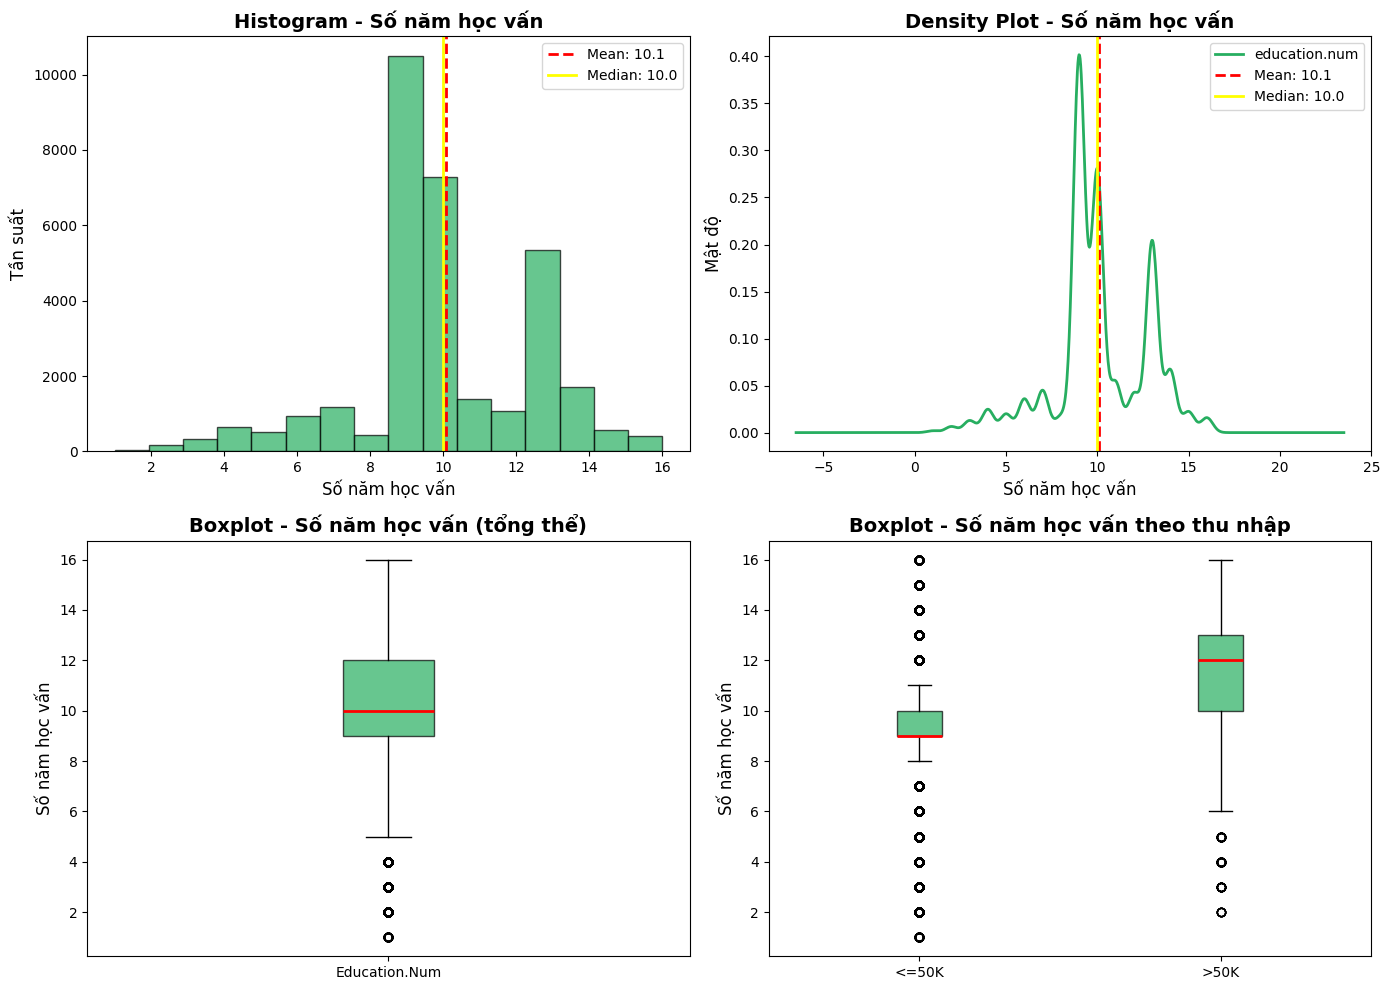


NHẬN XÉT:
- Số năm học vấn trung bình: ~10.1 năm, trung vị đạt 10.0 năm.
- Đa số người lao động tập trung ở mốc 9 năm (HS-grad), 10 năm (Some-college) và 13 năm (Bachelors).
- Sự khác biệt theo nhóm thu nhập: Nhóm >50K có trung vị học vấn là 12 năm, cao hơn đáng kể so với nhóm <=50K (9 năm).
- Trình độ học vấn cao tỷ lệ thuận rõ rệt với xác suất đạt mức thu nhập trên 50K.


In [18]:
# Vẽ Histogram, Density Plot và Boxplot cho education.num
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Histogram
axes[0, 0].hist(df_model['education.num'], bins=16, color='#27ae60', edgecolor='black', alpha=0.7)
axes[0, 0].axvline(df_model['education.num'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df_model["education.num"].mean():.1f}')
axes[0, 0].axvline(df_model['education.num'].median(), color='yellow', linestyle='-', linewidth=2, label=f'Median: {df_model["education.num"].median():.1f}')
axes[0, 0].set_title('Histogram - Số năm học vấn', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Số năm học vấn', fontsize=12)
axes[0, 0].set_ylabel('Tần suất', fontsize=12)
axes[0, 0].legend()

# 2. Density Plot
df_model['education.num'].plot(kind='density', ax=axes[0, 1], color='#27ae60', linewidth=2)
axes[0, 1].axvline(df_model['education.num'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df_model["education.num"].mean():.1f}')
axes[0, 1].axvline(df_model['education.num'].median(), color='yellow', linestyle='-', linewidth=2, label=f'Median: {df_model["education.num"].median():.1f}')
axes[0, 1].set_title('Density Plot - Số năm học vấn', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Số năm học vấn', fontsize=12)
axes[0, 1].set_ylabel('Mật độ', fontsize=12)
axes[0, 1].legend()

# 3. Boxplot tổng thể
axes[1, 0].boxplot(df_model['education.num'], vert=True, patch_artist=True,
                   boxprops=dict(facecolor='#27ae60', alpha=0.7),
                   medianprops=dict(color='red', linewidth=2))
axes[1, 0].set_title('Boxplot - Số năm học vấn (tổng thể)', fontsize=14, fontweight='bold')
axes[1, 0].set_ylabel('Số năm học vấn', fontsize=12)
axes[1, 0].set_xticks([1])
axes[1, 0].set_xticklabels(['Education.Num'])

# 4. Boxplot theo thu nhập
edu_by_income = [df_model[df_model['income'] == '<=50K']['education.num'],
                 df_model[df_model['income'] == '>50K']['education.num']]
axes[1, 1].boxplot(edu_by_income, vert=True, patch_artist=True,
                   boxprops=dict(facecolor='#27ae60', alpha=0.7),
                   medianprops=dict(color='red', linewidth=2))
axes[1, 1].set_title('Boxplot - Số năm học vấn theo thu nhập', fontsize=14, fontweight='bold')
axes[1, 1].set_ylabel('Số năm học vấn', fontsize=12)
axes[1, 1].set_xticks([1, 2])
axes[1, 1].set_xticklabels(['<=50K', '>50K'])

plt.tight_layout()
plt.show()

print("\nNHẬN XÉT:")
print("- Số năm học vấn trung bình: ~10.1 năm, trung vị đạt 10.0 năm.")
print("- Đa số người lao động tập trung ở mốc 9 năm (HS-grad), 10 năm (Some-college) và 13 năm (Bachelors).")
print("- Sự khác biệt theo nhóm thu nhập: Nhóm >50K có trung vị học vấn là 12 năm, cao hơn đáng kể so với nhóm <=50K (9 năm).")
print("- Trình độ học vấn cao tỷ lệ thuận rõ rệt với xác suất đạt mức thu nhập trên 50K.")


### 4.3. Phân tích số giờ làm việc mỗi tuần (hours.per.week)
Biến `hours.per.week` ghi nhận số giờ lao động trung bình hàng tuần của người khảo sát.


In [19]:
# Thống kê chi tiết cho biến hours.per.week
print("THỐNG KÊ CHI TIẾT - SỐ GIỜ LÀM VIỆC / TUẦN (HOURS.PER.WEEK):")
print("=" * 70)
hpw_stats = df_model['hours.per.week'].describe()
print(hpw_stats)
print(f"\nTrung vị (Median): {df_model['hours.per.week'].median():.1f}")
print(f"Độ lệch chuẩn (Std): {df_model['hours.per.week'].std():.2f}")
iqr_hpw = df_model['hours.per.week'].quantile(0.75) - df_model['hours.per.week'].quantile(0.25)
print(f"Khoảng tứ phân vị (IQR): {iqr_hpw:.1f}")


THỐNG KÊ CHI TIẾT - SỐ GIỜ LÀM VIỆC / TUẦN (HOURS.PER.WEEK):
count    32561.000000
mean        40.437456
std         12.347429
min          1.000000
25%         40.000000
50%         40.000000
75%         45.000000
max         99.000000
Name: hours.per.week, dtype: float64

Trung vị (Median): 40.0
Độ lệch chuẩn (Std): 12.35
Khoảng tứ phân vị (IQR): 5.0


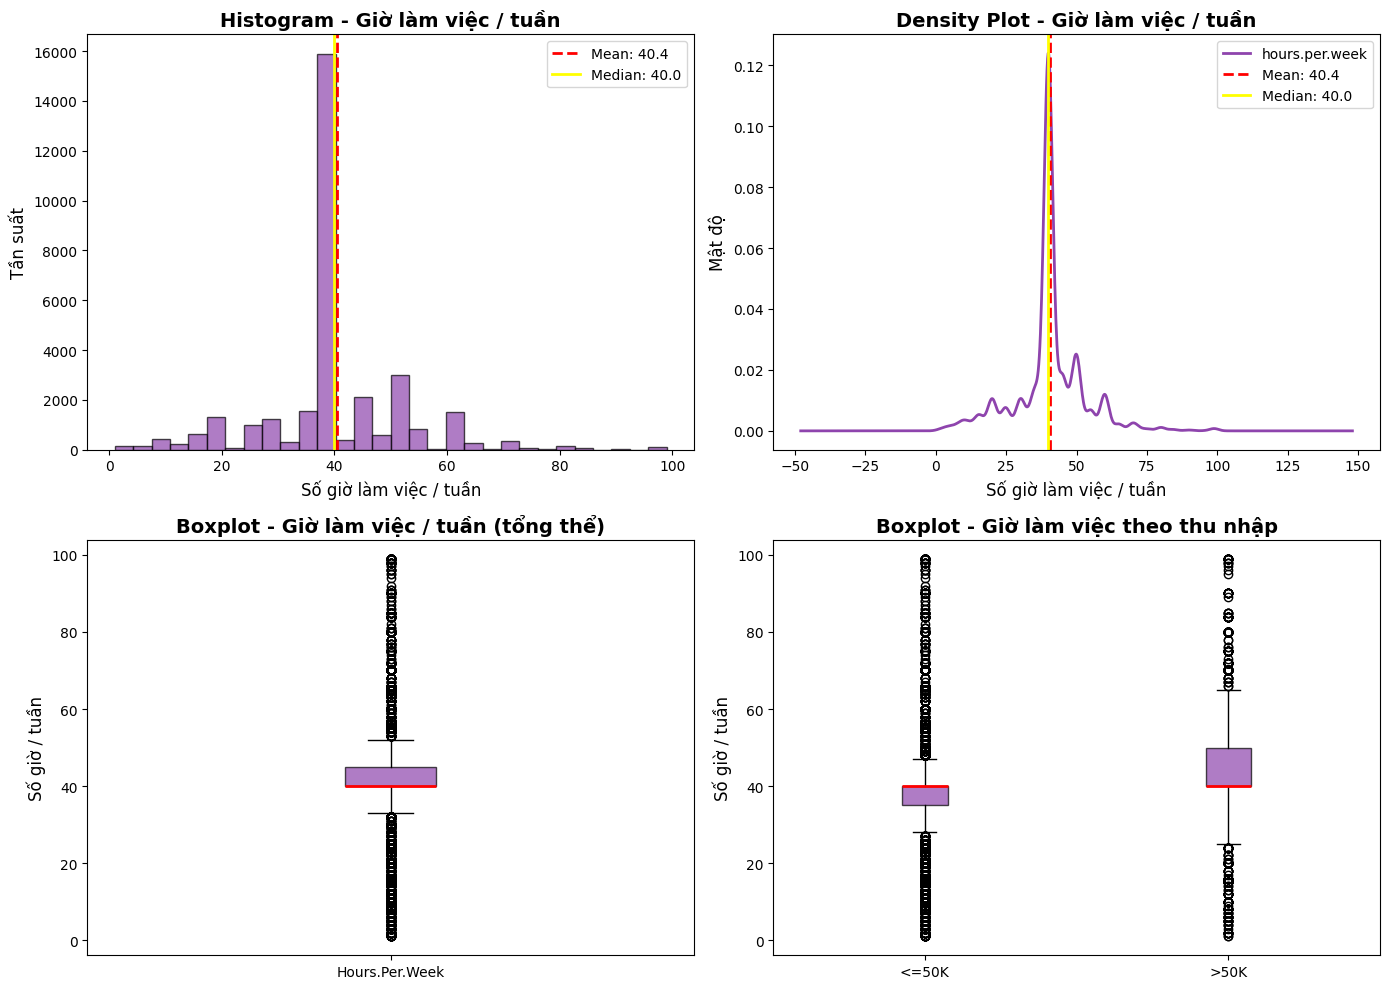


NHẬN XÉT:
- Số giờ làm việc bình quân: ~40.4 giờ/tuần; trung vị chính xác ở mốc 40.0 giờ/tuần (chuẩn toàn thời gian).
- Phân phối có đỉnh nhọn tập trung tại 40 giờ. Có rất nhiều ngoại lai (Outliers chiếm ~27.7%) do sự phân hóa giữa nhóm làm thêm giờ (>40h) và nhóm bán thời gian (<35h).
- Nhóm >50K làm việc trung bình 45.5 giờ/tuần, trong khi nhóm <=50K chỉ làm 38.8 giờ/tuần.


In [20]:
# Vẽ Histogram, Density Plot và Boxplot cho hours.per.week
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Histogram
axes[0, 0].hist(df_model['hours.per.week'], bins=30, color='#8e44ad', edgecolor='black', alpha=0.7)
axes[0, 0].axvline(df_model['hours.per.week'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df_model["hours.per.week"].mean():.1f}')
axes[0, 0].axvline(df_model['hours.per.week'].median(), color='yellow', linestyle='-', linewidth=2, label=f'Median: {df_model["hours.per.week"].median():.1f}')
axes[0, 0].set_title('Histogram - Giờ làm việc / tuần', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Số giờ làm việc / tuần', fontsize=12)
axes[0, 0].set_ylabel('Tần suất', fontsize=12)
axes[0, 0].legend()

# 2. Density Plot
df_model['hours.per.week'].plot(kind='density', ax=axes[0, 1], color='#8e44ad', linewidth=2)
axes[0, 1].axvline(df_model['hours.per.week'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df_model["hours.per.week"].mean():.1f}')
axes[0, 1].axvline(df_model['hours.per.week'].median(), color='yellow', linestyle='-', linewidth=2, label=f'Median: {df_model["hours.per.week"].median():.1f}')
axes[0, 1].set_title('Density Plot - Giờ làm việc / tuần', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Số giờ làm việc / tuần', fontsize=12)
axes[0, 1].set_ylabel('Mật độ', fontsize=12)
axes[0, 1].legend()

# 3. Boxplot tổng thể
axes[1, 0].boxplot(df_model['hours.per.week'], vert=True, patch_artist=True,
                   boxprops=dict(facecolor='#8e44ad', alpha=0.7),
                   medianprops=dict(color='red', linewidth=2))
axes[1, 0].set_title('Boxplot - Giờ làm việc / tuần (tổng thể)', fontsize=14, fontweight='bold')
axes[1, 0].set_ylabel('Số giờ / tuần', fontsize=12)
axes[1, 0].set_xticks([1])
axes[1, 0].set_xticklabels(['Hours.Per.Week'])

# 4. Boxplot theo thu nhập
hpw_by_income = [df_model[df_model['income'] == '<=50K']['hours.per.week'],
                 df_model[df_model['income'] == '>50K']['hours.per.week']]
axes[1, 1].boxplot(hpw_by_income, vert=True, patch_artist=True,
                   boxprops=dict(facecolor='#8e44ad', alpha=0.7),
                   medianprops=dict(color='red', linewidth=2))
axes[1, 1].set_title('Boxplot - Giờ làm việc theo thu nhập', fontsize=14, fontweight='bold')
axes[1, 1].set_ylabel('Số giờ / tuần', fontsize=12)
axes[1, 1].set_xticks([1, 2])
axes[1, 1].set_xticklabels(['<=50K', '>50K'])

plt.tight_layout()
plt.show()

print("\nNHẬN XÉT:")
print("- Số giờ làm việc bình quân: ~40.4 giờ/tuần; trung vị chính xác ở mốc 40.0 giờ/tuần (chuẩn toàn thời gian).")
print("- Phân phối có đỉnh nhọn tập trung tại 40 giờ. Có rất nhiều ngoại lai (Outliers chiếm ~27.7%) do sự phân hóa giữa nhóm làm thêm giờ (>40h) và nhóm bán thời gian (<35h).")
print("- Nhóm >50K làm việc trung bình 45.5 giờ/tuần, trong khi nhóm <=50K chỉ làm 38.8 giờ/tuần.")


### 4.4. Phân tích thu nhập từ vốn (capital.gain)
Biến `capital.gain` ghi nhận khoản lợi nhuận tài chính từ vốn đầu tư.


In [21]:
# Thống kê chi tiết cho biến capital.gain
print("THỐNG KÊ CHI TIẾT - THU NHẬP TỪ VỐN (CAPITAL.GAIN):")
print("=" * 70)
print(df_model['capital.gain'].describe())
print(f"\nTỷ lệ người có capital.gain = 0: {(df_model['capital.gain'] == 0).mean() * 100:.2f}%")
print(f"Trung vị (Median): {df_model['capital.gain'].median():.1f}")
print(f"Độ lệch (Skewness): {df_model['capital.gain'].skew():.2f}")


THỐNG KÊ CHI TIẾT - THU NHẬP TỪ VỐN (CAPITAL.GAIN):
count    32561.000000
mean      1077.648844
std       7385.292085
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max      99999.000000
Name: capital.gain, dtype: float64

Tỷ lệ người có capital.gain = 0: 91.67%
Trung vị (Median): 0.0
Độ lệch (Skewness): 11.95


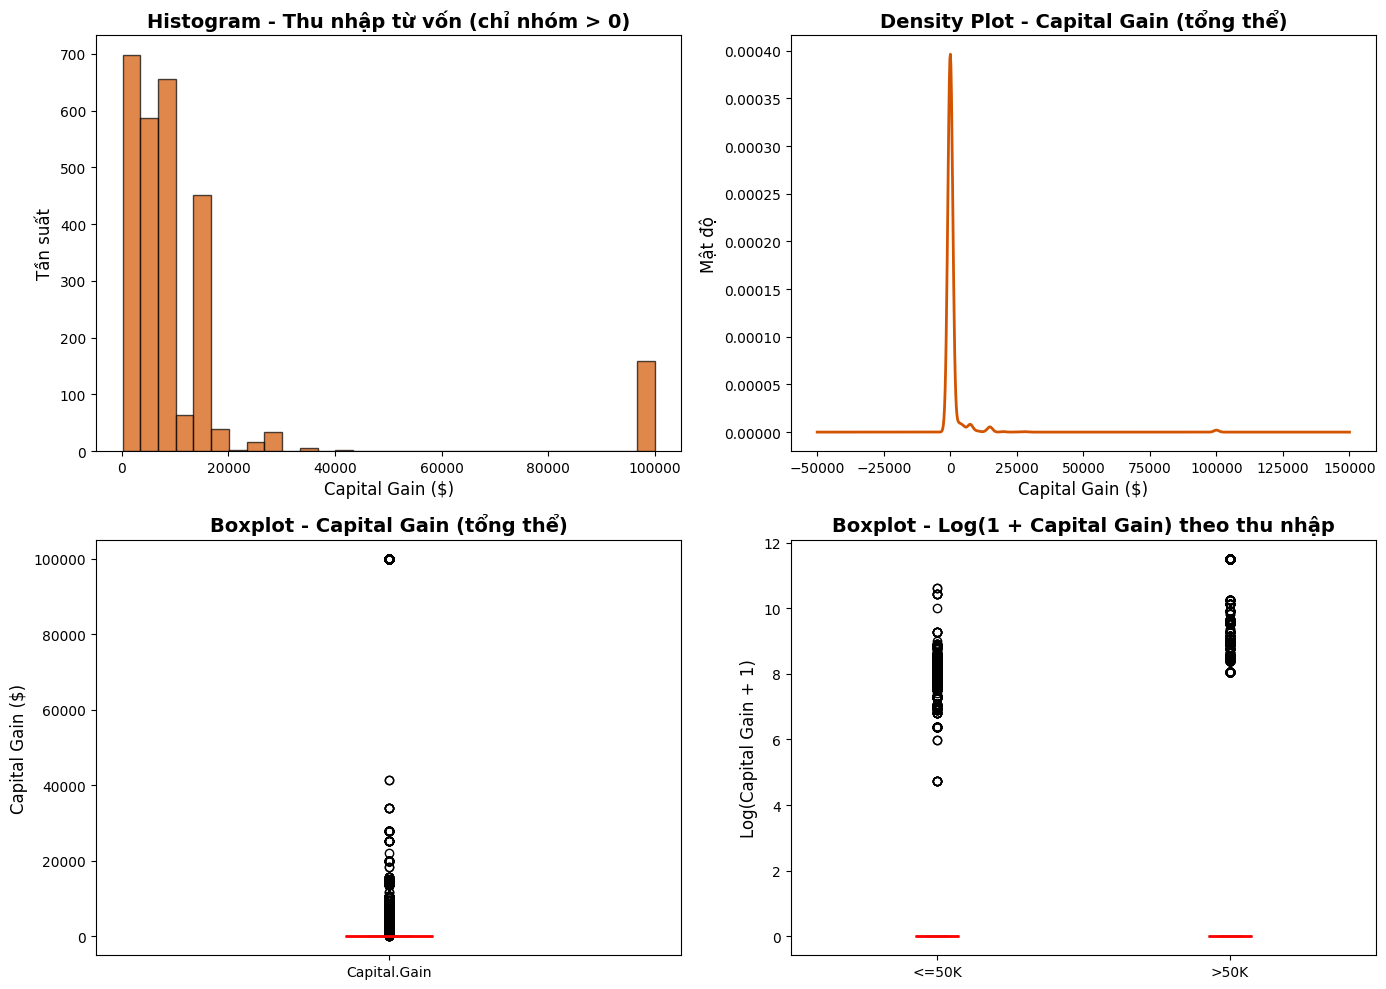


NHẬN XÉT:
- Phân phối cực kỳ lệch phải (Skewness = 11.95). Có hơn 91.6% quan sát bằng 0.
- Ở nhóm >50K, số lượng người có thu nhập từ vốn và giá trị thu nhập vốn trung bình (~$4.007) cao vượt bậc so với nhóm <=50K (~$148).
- Biến capital.gain xuất hiện giá trị ngoại lai cực đại tại $99.999 (giới hạn trần khảo sát).


In [22]:
# Vẽ Histogram, Density Plot và Boxplot cho capital.gain
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Histogram (lấy nhóm > 0 để quan sát rõ phân phối)
axes[0, 0].hist(df_model[df_model['capital.gain'] > 0]['capital.gain'], bins=30, color='#d35400', edgecolor='black', alpha=0.7)
axes[0, 0].set_title('Histogram - Thu nhập từ vốn (chỉ nhóm > 0)', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Capital Gain ($)', fontsize=12)
axes[0, 0].set_ylabel('Tần suất', fontsize=12)

# 2. Density Plot
df_model['capital.gain'].plot(kind='density', ax=axes[0, 1], color='#d35400', linewidth=2)
axes[0, 1].set_title('Density Plot - Capital Gain (tổng thể)', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Capital Gain ($)', fontsize=12)
axes[0, 1].set_ylabel('Mật độ', fontsize=12)

# 3. Boxplot tổng thể
axes[1, 0].boxplot(df_model['capital.gain'], vert=True, patch_artist=True,
                   boxprops=dict(facecolor='#d35400', alpha=0.7),
                   medianprops=dict(color='red', linewidth=2))
axes[1, 0].set_title('Boxplot - Capital Gain (tổng thể)', fontsize=14, fontweight='bold')
axes[1, 0].set_ylabel('Capital Gain ($)', fontsize=12)
axes[1, 0].set_xticks([1])
axes[1, 0].set_xticklabels(['Capital.Gain'])

# 4. Boxplot theo thu nhập (dùng log1p để biểu diễn trực quan do chênh lệch thang đo)
cap_by_income = [np.log1p(df_model[df_model['income'] == '<=50K']['capital.gain']),
                 np.log1p(df_model[df_model['income'] == '>50K']['capital.gain'])]
axes[1, 1].boxplot(cap_by_income, vert=True, patch_artist=True,
                   boxprops=dict(facecolor='#d35400', alpha=0.7),
                   medianprops=dict(color='red', linewidth=2))
axes[1, 1].set_title('Boxplot - Log(1 + Capital Gain) theo thu nhập', fontsize=14, fontweight='bold')
axes[1, 1].set_ylabel('Log(Capital Gain + 1)', fontsize=12)
axes[1, 1].set_xticks([1, 2])
axes[1, 1].set_xticklabels(['<=50K', '>50K'])

plt.tight_layout()
plt.show()

print("\nNHẬN XÉT:")
print("- Phân phối cực kỳ lệch phải (Skewness = 11.95). Có hơn 91.6% quan sát bằng 0.")
print("- Ở nhóm >50K, số lượng người có thu nhập từ vốn và giá trị thu nhập vốn trung bình (~$4.007) cao vượt bậc so với nhóm <=50K (~$148).")
print("- Biến capital.gain xuất hiện giá trị ngoại lai cực đại tại $99.999 (giới hạn trần khảo sát).")


### 4.5. Phân tích khoản lỗ vốn (capital.loss)
Biến `capital.loss` ghi nhận khoản thua lỗ từ các hoạt động đầu tư tài chính.


In [23]:
# Thống kê chi tiết cho biến capital.loss
print("THỐNG KÊ CHI TIẾT - KHOẢN LỖ VỐN (CAPITAL.LOSS):")
print("=" * 70)
print(df_model['capital.loss'].describe())
print(f"\nTỷ lệ người có capital.loss = 0: {(df_model['capital.loss'] == 0).mean() * 100:.2f}%")
print(f"Trung vị (Median): {df_model['capital.loss'].median():.1f}")
print(f"Độ lệch (Skewness): {df_model['capital.loss'].skew():.2f}")


THỐNG KÊ CHI TIẾT - KHOẢN LỖ VỐN (CAPITAL.LOSS):
count    32561.000000
mean        87.303830
std        402.960219
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max       4356.000000
Name: capital.loss, dtype: float64

Tỷ lệ người có capital.loss = 0: 95.33%
Trung vị (Median): 0.0
Độ lệch (Skewness): 4.59


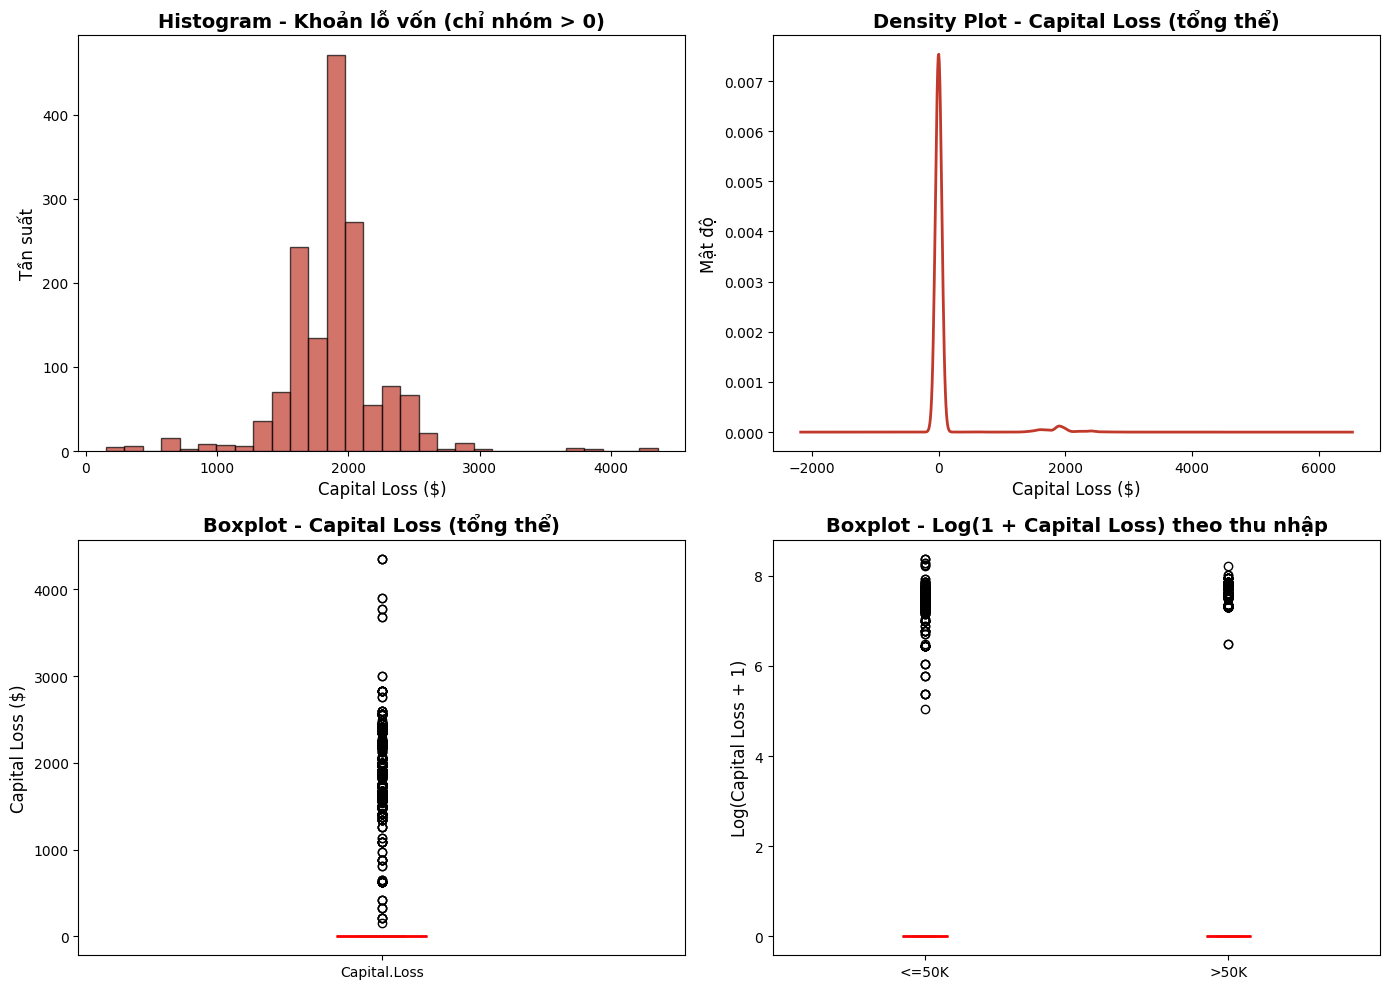


NHẬN XÉT:
- Tương tự capital.gain, hơn 95% quan sát có capital.loss = 0.
- Nhóm >50K có mức lỗ vốn trung bình (~$195) cao hơn nhóm <=50K (~$53), phản ánh nhóm thu nhập cao thường tham gia thị trường tài chính nhiều hơn.


In [24]:
# Vẽ Histogram, Density Plot và Boxplot cho capital.loss
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Histogram (nhóm > 0)
axes[0, 0].hist(df_model[df_model['capital.loss'] > 0]['capital.loss'], bins=30, color='#c0392b', edgecolor='black', alpha=0.7)
axes[0, 0].set_title('Histogram - Khoản lỗ vốn (chỉ nhóm > 0)', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Capital Loss ($)', fontsize=12)
axes[0, 0].set_ylabel('Tần suất', fontsize=12)

# 2. Density Plot
df_model['capital.loss'].plot(kind='density', ax=axes[0, 1], color='#c0392b', linewidth=2)
axes[0, 1].set_title('Density Plot - Capital Loss (tổng thể)', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Capital Loss ($)', fontsize=12)
axes[0, 1].set_ylabel('Mật độ', fontsize=12)

# 3. Boxplot tổng thể
axes[1, 0].boxplot(df_model['capital.loss'], vert=True, patch_artist=True,
                   boxprops=dict(facecolor='#c0392b', alpha=0.7),
                   medianprops=dict(color='red', linewidth=2))
axes[1, 0].set_title('Boxplot - Capital Loss (tổng thể)', fontsize=14, fontweight='bold')
axes[1, 0].set_ylabel('Capital Loss ($)', fontsize=12)
axes[1, 0].set_xticks([1])
axes[1, 0].set_xticklabels(['Capital.Loss'])

# 4. Boxplot theo thu nhập
cap_loss_by_income = [np.log1p(df_model[df_model['income'] == '<=50K']['capital.loss']),
                      np.log1p(df_model[df_model['income'] == '>50K']['capital.loss'])]
axes[1, 1].boxplot(cap_loss_by_income, vert=True, patch_artist=True,
                   boxprops=dict(facecolor='#c0392b', alpha=0.7),
                   medianprops=dict(color='red', linewidth=2))
axes[1, 1].set_title('Boxplot - Log(1 + Capital Loss) theo thu nhập', fontsize=14, fontweight='bold')
axes[1, 1].set_ylabel('Log(Capital Loss + 1)', fontsize=12)
axes[1, 1].set_xticks([1, 2])
axes[1, 1].set_xticklabels(['<=50K', '>50K'])

plt.tight_layout()
plt.show()

print("\nNHẬN XÉT:")
print("- Tương tự capital.gain, hơn 95% quan sát có capital.loss = 0.")
print("- Nhóm >50K có mức lỗ vốn trung bình (~$195) cao hơn nhóm <=50K (~$53), phản ánh nhóm thu nhập cao thường tham gia thị trường tài chính nhiều hơn.")


### 4.6. Bảng tổng hợp các giá trị ngoại lai (Outliers) theo quy tắc 1.5 * IQR


In [25]:
# Thống kê Outliers cho tất cả các biến định lượng
num_cols = ['age', 'education.num', 'hours.per.week', 'capital.gain', 'capital.loss']
outlier_list = []

for col in num_cols:
    s = df_model[col]
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers_count = ((s < lower_bound) | (s > upper_bound)).sum()
    
    outlier_list.append({
        'Biến định lượng': col,
        'Mean': round(s.mean(), 2),
        'Median': round(s.median(), 2),
        'Q1 (25%)': round(q1, 2),
        'Q3 (75%)': round(q3, 2),
        'IQR': round(iqr, 2),
        'Ngưỡng dưới (Lower)': round(lower_bound, 2),
        'Ngưỡng trên (Upper)': round(upper_bound, 2),
        'Số lượng Outliers': outliers_count,
        'Tỷ lệ Outliers (%)': round(outliers_count / len(s) * 100, 2)
    })

df_outliers = pd.DataFrame(outlier_list)
print("BẢNG TỔNG HỢP NGOẠI LAI (OUTLIERS):")
display(df_outliers)


BẢNG TỔNG HỢP NGOẠI LAI (OUTLIERS):


,Biến định lượng,Mean,Median,Q1 (25%),Q3 (75%),IQR,Ngưỡng dưới (Lower),Ngưỡng trên (Upper),Số lượng Outliers,Tỷ lệ Outliers (%)
0,age,38.58,37.0,28.0,48.0,20.0,-2.0,78.0,143,0.44
1,education.num,10.08,10.0,9.0,12.0,3.0,4.5,16.5,1198,3.68
2,hours.per.week,40.44,40.0,40.0,45.0,5.0,32.5,52.5,9008,27.66
3,capital.gain,1077.65,0.0,0.0,0.0,0.0,0.0,0.0,2712,8.33
4,capital.loss,87.30,0.0,0.0,0.0,0.0,0.0,0.0,1519,4.67


# Chương 5: Phân tích nhóm tỷ lệ lồng nhau (Nested Proportions)
Chương này đi sâu vào việc khảo sát mối liên hệ đa chiều giữa các cặp biến nhân khẩu học kết hợp và xác suất đạt mức thu nhập >50K.


### 5.1. Kết hợp Trình độ học vấn và Giới tính (Education × Sex)


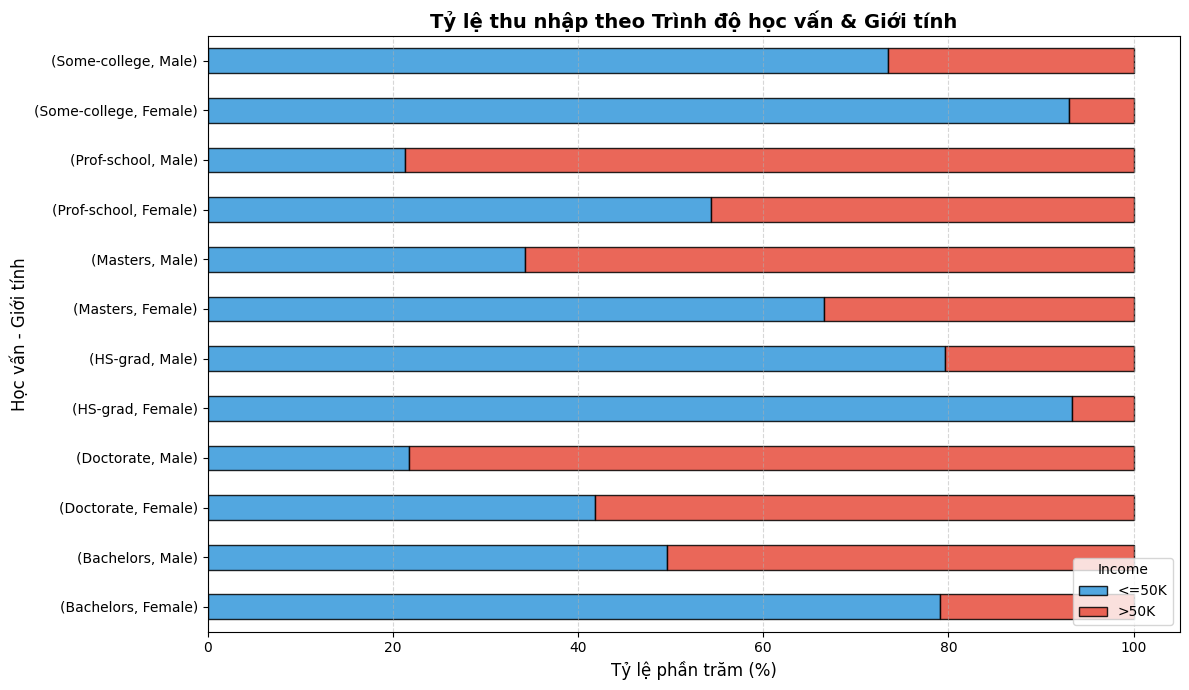


NHẬN XÉT:
- Ở mọi cấp bậc học vấn, nam giới luôn có tỷ lệ thu nhập >50K cao hơn so với nữ giới.
- Tuy nhiên, bằng cấp cao (Doctorate, Prof-school, Masters) giúp nâng vọt tỷ lệ >50K ở cả 2 giới (lên tới >70% ở nam và >40% ở nữ).


In [26]:
# Bảng chéo và biểu đồ cột chồng 100% cho Education x Sex
ct_edu_sex = pd.crosstab(index=[df_model['education'], df_model['sex']], columns=df_model['income'], normalize='index') * 100

top_edus = ['HS-grad', 'Some-college', 'Bachelors', 'Masters', 'Prof-school', 'Doctorate']
ct_sub = ct_edu_sex.loc[ct_edu_sex.index.get_level_values(0).isin(top_edus)]

fig, ax = plt.subplots(figsize=(12, 7))
ct_sub.plot(kind='barh', stacked=True, color=['#3498db', '#e74c3c'], ax=ax, edgecolor='black', alpha=0.85)
ax.set_title('Tỷ lệ thu nhập theo Trình độ học vấn & Giới tính', fontsize=14, fontweight='bold')
ax.set_xlabel('Tỷ lệ phần trăm (%)', fontsize=12)
ax.set_ylabel('Học vấn - Giới tính', fontsize=12)
ax.legend(title='Income', loc='lower right')
ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print("\nNHẬN XÉT:")
print("- Ở mọi cấp bậc học vấn, nam giới luôn có tỷ lệ thu nhập >50K cao hơn so với nữ giới.")
print("- Tuy nhiên, bằng cấp cao (Doctorate, Prof-school, Masters) giúp nâng vọt tỷ lệ >50K ở cả 2 giới (lên tới >70% ở nam và >40% ở nữ).")


### 5.2. Kết hợp Nghề nghiệp và Giới tính (Occupation × Sex)


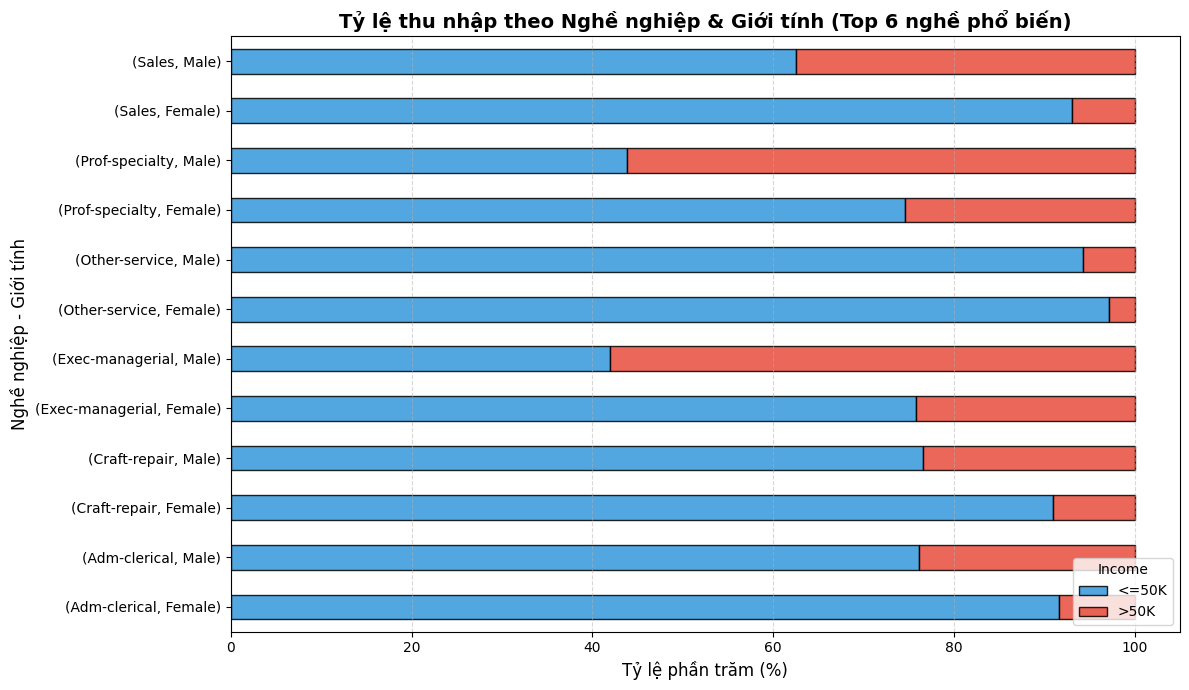


NHẬN XÉT:
- Vị trí quản lý (Exec-managerial) và chuyên môn cao (Prof-specialty) có tỷ lệ thu nhập >50K cao nhất ở cả 2 giới.
- Các nhóm nghề dịch vụ cá nhân (Other-service) và hành chính (Adm-clerical) có tỷ lệ đạt >50K rất khiêm tốn (<15%).


In [27]:
# Bảng chéo và biểu đồ cột chồng 100% cho Occupation x Sex (Top 6 nghề phổ biến nhất)
top_6_occ = df_model['occupation'].value_counts().head(6).index
df_occ_sub = df_model[df_model['occupation'].isin(top_6_occ)]

ct_occ_sex = pd.crosstab(index=[df_occ_sub['occupation'], df_occ_sub['sex']], columns=df_occ_sub['income'], normalize='index') * 100

fig, ax = plt.subplots(figsize=(12, 7))
ct_occ_sex.plot(kind='barh', stacked=True, color=['#3498db', '#e74c3c'], ax=ax, edgecolor='black', alpha=0.85)
ax.set_title('Tỷ lệ thu nhập theo Nghề nghiệp & Giới tính (Top 6 nghề phổ biến)', fontsize=14, fontweight='bold')
ax.set_xlabel('Tỷ lệ phần trăm (%)', fontsize=12)
ax.set_ylabel('Nghề nghiệp - Giới tính', fontsize=12)
ax.legend(title='Income', loc='lower right')
ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print("\nNHẬN XÉT:")
print("- Vị trí quản lý (Exec-managerial) và chuyên môn cao (Prof-specialty) có tỷ lệ thu nhập >50K cao nhất ở cả 2 giới.")
print("- Các nhóm nghề dịch vụ cá nhân (Other-service) và hành chính (Adm-clerical) có tỷ lệ đạt >50K rất khiêm tốn (<15%).")


### 5.3. Kết hợp Trình độ học vấn và Tình trạng hôn nhân (Education × Marital.Status)


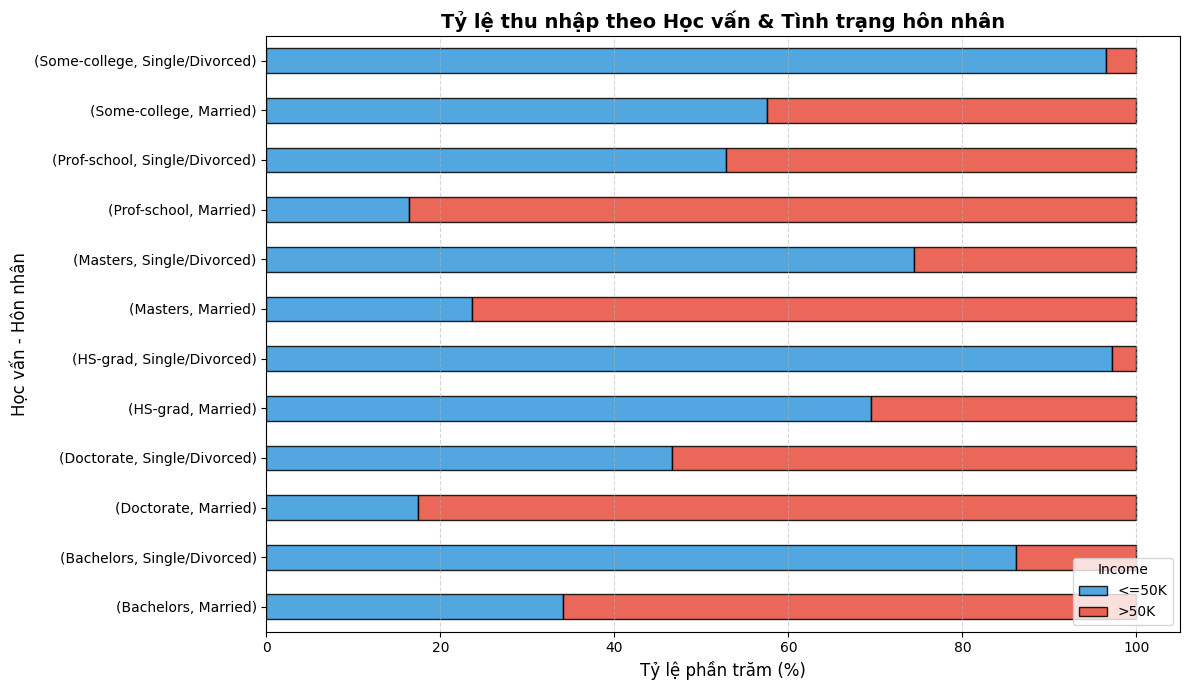


NHẬN XÉT:
- Yếu tố hôn nhân có tác động cực kỳ mạnh: Nhóm đã kết hôn (Married) kết hợp học vấn cao (Bachelors trở lên) có tỷ lệ thu nhập >50K vượt trội (>60-75%).
- Ngược lại, nhóm độc thân/ly hôn dù có bằng đại học thì tỷ lệ >50K vẫn thấp hơn đáng kể.


In [28]:
# Bảng chéo và biểu đồ cột chồng cho Education x Marital Status
# Gom nhóm tình trạng hôn nhân thành Married và Non-Married
df_model['is_married'] = df_model['marital.status'].apply(lambda x: 'Married' if 'Married' in str(x) else 'Single/Divorced')

ct_edu_mar = pd.crosstab(index=[df_model['education'], df_model['is_married']], columns=df_model['income'], normalize='index') * 100
ct_edu_mar_sub = ct_edu_mar.loc[ct_edu_mar.index.get_level_values(0).isin(top_edus)]

fig, ax = plt.subplots(figsize=(12, 7))
ct_edu_mar_sub.plot(kind='barh', stacked=True, color=['#3498db', '#e74c3c'], ax=ax, edgecolor='black', alpha=0.85)
ax.set_title('Tỷ lệ thu nhập theo Học vấn & Tình trạng hôn nhân', fontsize=14, fontweight='bold')
ax.set_xlabel('Tỷ lệ phần trăm (%)', fontsize=12)
ax.set_ylabel('Học vấn - Hôn nhân', fontsize=12)
ax.legend(title='Income', loc='lower right')
ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print("\nNHẬN XÉT:")
print("- Yếu tố hôn nhân có tác động cực kỳ mạnh: Nhóm đã kết hôn (Married) kết hợp học vấn cao (Bachelors trở lên) có tỷ lệ thu nhập >50K vượt trội (>60-75%).")
print("- Ngược lại, nhóm độc thân/ly hôn dù có bằng đại học thì tỷ lệ >50K vẫn thấp hơn đáng kể.")


### 5.4. Kết hợp Nghề nghiệp và Khung giờ làm việc (Occupation × Hours Group)


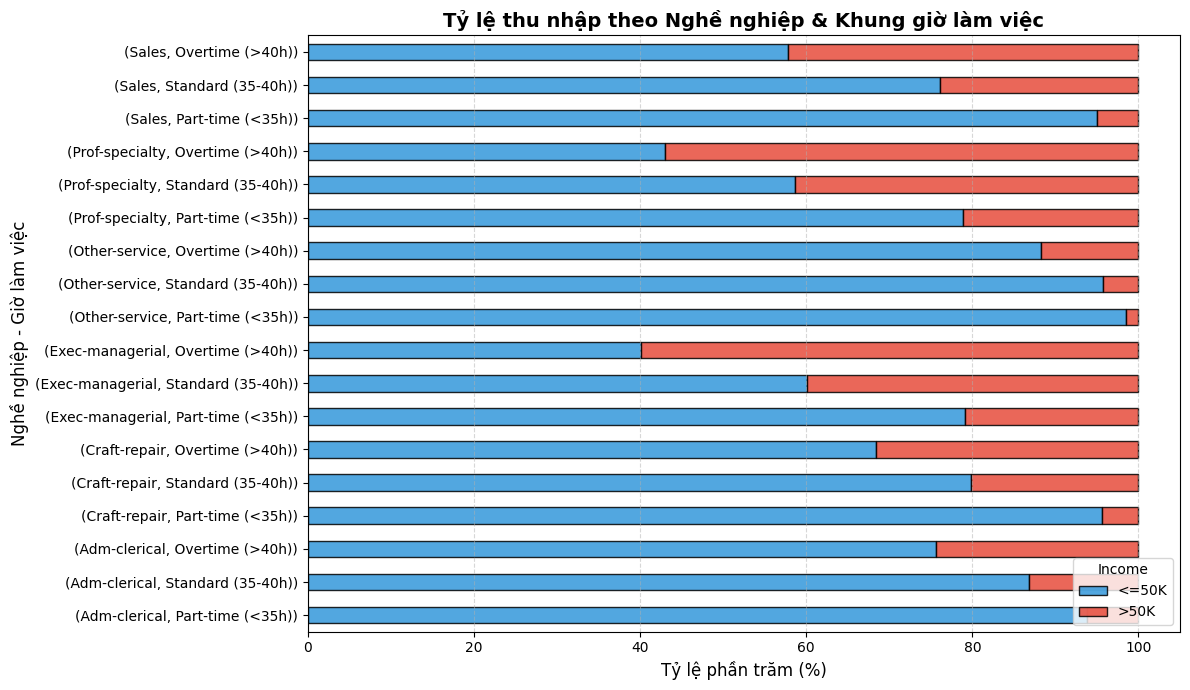


NHẬN XÉT:
- Chế độ làm việc tăng ca (Overtime >40h) tại các vị trí quản lý hoặc chuyên môn cao đem lại xác suất đạt >50K cao nhất (hơn 60%).
- Những người làm bán thời gian (Part-time <35h) hầu như chỉ đạt mức thu nhập <=50K.


In [29]:
# Phân nhóm giờ làm việc: Part-time (<35h), Standard (35-40h), Overtime (>40h)
df_model['hours_group'] = pd.cut(
    df_model['hours.per.week'],
    bins=[0, 34, 40, 100],
    labels=['Part-time (<35h)', 'Standard (35-40h)', 'Overtime (>40h)']
)

ct_occ_hrs = pd.crosstab(index=[df_occ_sub['occupation'], df_model.loc[df_occ_sub.index, 'hours_group']], columns=df_occ_sub['income'], normalize='index') * 100

fig, ax = plt.subplots(figsize=(12, 7))
ct_occ_hrs.plot(kind='barh', stacked=True, color=['#3498db', '#e74c3c'], ax=ax, edgecolor='black', alpha=0.85)
ax.set_title('Tỷ lệ thu nhập theo Nghề nghiệp & Khung giờ làm việc', fontsize=14, fontweight='bold')
ax.set_xlabel('Tỷ lệ phần trăm (%)', fontsize=12)
ax.set_ylabel('Nghề nghiệp - Giờ làm việc', fontsize=12)
ax.legend(title='Income', loc='lower right')
ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print("\nNHẬN XÉT:")
print("- Chế độ làm việc tăng ca (Overtime >40h) tại các vị trí quản lý hoặc chuyên môn cao đem lại xác suất đạt >50K cao nhất (hơn 60%).")
print("- Những người làm bán thời gian (Part-time <35h) hầu như chỉ đạt mức thu nhập <=50K.")


# Chương 6: Mối liên hệ đa biến và Kiểm định thống kê Chi-Square
Chương này đánh giá mức độ tương quan giữa các biến định lượng và thực hiện kiểm định giả thuyết tính độc lập Chi-square giữa các biến phân loại và biến mục tiêu `income`.


### 6.1. Ma trận tương quan Pearson giữa các biến số


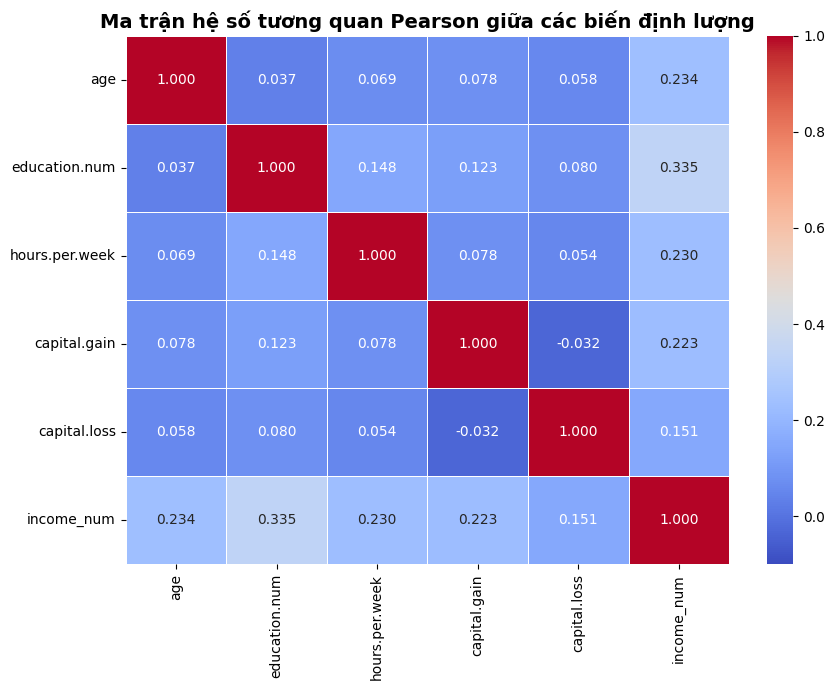


NHẬN XÉT TƯƠNG QUAN:
- education.num có hệ số tương quan dương cao nhất với biến thu nhập income_num (r = +0.335).
- Độ tuổi (age) xếp thứ hai (r = +0.234), tiếp theo là hours.per.week (r = +0.230) và capital.gain (r = +0.223).
- Hệ số tương quan chéo giữa các biến độc lập đều ở mức thấp (<0.15), cho thấy không có hiện tượng đa cộng tuyến (multicollinearity).


In [30]:
# Tạo biến mã hóa nhị phân income_num (0: <=50K, 1: >50K)
df_model['income_num'] = (df_model['income'] == '>50K').astype(int)

num_features = ['age', 'education.num', 'hours.per.week', 'capital.gain', 'capital.loss', 'income_num']
corr_matrix = df_model[num_features].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', vmin=-0.1, vmax=1.0, linewidths=0.5, ax=ax)
ax.set_title('Ma trận hệ số tương quan Pearson giữa các biến định lượng', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print("\nNHẬN XÉT TƯƠNG QUAN:")
print("- education.num có hệ số tương quan dương cao nhất với biến thu nhập income_num (r = +0.335).")
print("- Độ tuổi (age) xếp thứ hai (r = +0.234), tiếp theo là hours.per.week (r = +0.230) và capital.gain (r = +0.223).")
print("- Hệ số tương quan chéo giữa các biến độc lập đều ở mức thấp (<0.15), cho thấy không có hiện tượng đa cộng tuyến (multicollinearity).")


### 6.2. Kiểm định Chi-Square về tính độc lập giữa biến phân loại và Income
- **Giả thuyết H0:** Biến phân loại và biến thu nhập là độc lập nhau (không có mối liên hệ).
- **Giả thuyết H1:** Biến phân loại và biến thu nhập có mối liên hệ có ý nghĩa thống kê.
- **Mức ý nghĩa:** $\alpha = 0.05$.


In [31]:
# Thực hiện kiểm định Chi-square cho 4 cặp biến phân loại chính
cat_tests = [
    ('education', 'Học vấn x Thu nhập (Education x Income)'),
    ('sex', 'Giới tính x Thu nhập (Sex x Income)'),
    ('occupation', 'Nghề nghiệp x Thu nhập (Occupation x Income)'),
    ('marital.status', 'Tình trạng hôn nhân x Thu nhập (Marital Status x Income)')
]

chi_summary = []

print("KẾT QUẢ KIỂM ĐỊNH CHI-SQUARE VỀ TÍNH ĐỘC LẬP:")
print("=" * 80)

for col, label in cat_tests:
    contingency = pd.crosstab(df_model[col], df_model['income'])
    chi2, p_val, dof, _ = chi2_contingency(contingency)
    
    is_sig = p_val < 0.05
    decision = "Bác bỏ H0 (Có liên hệ chặt chẽ)" if is_sig else "Chấp nhận H0"
    
    chi_summary.append({
        'Cặp biến kiểm định': label,
        'Chi-Square (χ²)': round(chi2, 2),
        'Bậc tự do (dof)': dof,
        'p-value': f'{p_val:.4e}',
        'Kết luận (α = 0.05)': decision
    })
    
    print(f"[*] {label}:")
    print(f"    Chi2 = {chi2:.2f} | Bậc tự do = {dof} | p-value = {p_val:.4e}")
    print(f"    -> Kết luận: {decision}\n")

df_chi_table = pd.DataFrame(chi_summary)
display(df_chi_table)

print("\nKẾT LUẬN CHUNG VỀ KIỂM ĐỊNH CHI-SQUARE:")
print("- Tất cả 4 kiểm định đều cho p-value xấp xỉ 0 (< 0.0001), nhỏ hơn rất nhiều so với mức ý nghĩa alpha = 0.05.")
print("- Nhóm hoàn toàn bác bỏ giả thuyết H0, khẳng định các đặc trưng nhân khẩu học (Học vấn, Hôn nhân, Giới tính, Nghề nghiệp) đều có ảnh hưởng mang tính thống kê sâu sắc đến mức thu nhập.")


KẾT QUẢ KIỂM ĐỊNH CHI-SQUARE VỀ TÍNH ĐỘC LẬP:
[*] Học vấn x Thu nhập (Education x Income):
    Chi2 = 4429.65 | Bậc tự do = 15 | p-value = 0.0000e+00
    -> Kết luận: Bác bỏ H0 (Có liên hệ chặt chẽ)

[*] Giới tính x Thu nhập (Sex x Income):
    Chi2 = 1517.81 | Bậc tự do = 1 | p-value = 0.0000e+00
    -> Kết luận: Bác bỏ H0 (Có liên hệ chặt chẽ)

[*] Nghề nghiệp x Thu nhập (Occupation x Income):
    Chi2 = 4031.97 | Bậc tự do = 14 | p-value = 0.0000e+00
    -> Kết luận: Bác bỏ H0 (Có liên hệ chặt chẽ)

[*] Tình trạng hôn nhân x Thu nhập (Marital Status x Income):
    Chi2 = 6517.74 | Bậc tự do = 6 | p-value = 0.0000e+00
    -> Kết luận: Bác bỏ H0 (Có liên hệ chặt chẽ)



,Cặp biến kiểm định,Chi-Square (χ²),Bậc tự do (dof),p-value,Kết luận (α = 0.05)
0,Học vấn x Thu nhập (Education x Income),4429.65,15,0.0000e+00,Bác bỏ H0 (Có liên hệ chặt chẽ)
1,Giới tính x Thu nhập (Sex x Income),1517.81,1,0.0000e+00,Bác bỏ H0 (Có liên hệ chặt chẽ)
2,Nghề nghiệp x Thu nhập (Occupation x Income),4031.97,14,0.0000e+00,Bác bỏ H0 (Có liên hệ chặt chẽ)
3,Tình trạng hôn nhân x Thu nhập (Marital Status...,6517.74,6,0.0000e+00,Bác bỏ H0 (Có liên hệ chặt chẽ)



KẾT LUẬN CHUNG VỀ KIỂM ĐỊNH CHI-SQUARE:
- Tất cả 4 kiểm định đều cho p-value xấp xỉ 0 (< 0.0001), nhỏ hơn rất nhiều so với mức ý nghĩa alpha = 0.05.
- Nhóm hoàn toàn bác bỏ giả thuyết H0, khẳng định các đặc trưng nhân khẩu học (Học vấn, Hôn nhân, Giới tính, Nghề nghiệp) đều có ảnh hưởng mang tính thống kê sâu sắc đến mức thu nhập.
